# Level 1 — Task 2: Descriptive Analysis
**Cognifyz Technologies | Data Science Internship**

This notebook performs descriptive analysis of the restaurant dataset. It summarizes numerical variables, explores the distributions of `Country Code`, `City`, and `Cuisines`, identifies the 10 cities with the most restaurants and the 10 most frequently listed cuisines, and presents evidence-based insights.

**Dataset path:** `../dataset/Dataset.csv`  
**Expected working directory:** `Cognifyz_Internship/Level1/`

> Run the notebook from the `Level1` directory so the relative dataset path resolves correctly.

## 1. Import libraries

We use **Pandas** for data manipulation and summary statistics, and **Matplotlib/Seaborn** for visualizations.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)

## 2. Load the dataset

In [2]:
DATA_PATH = "../dataset/Dataset.csv"
df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully: {DATA_PATH}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
display(df.head())

Dataset loaded successfully: ../dataset/Dataset.csv
Rows: 9,551 | Columns: 21


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenue, Poblaci...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Makati City",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi Village, ...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Makati City",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Mandaluyong ...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, Ortigas, Ma...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandaluyong City",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas, Mandaluy...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandaluyong City",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


## 3. Data overview and quality checks

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.rename("Data type").to_frame())

print("\nMissing values by column:")
missing_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Values", ascending=False)
display(missing_summary)

print(f"\nDuplicate rows: {df.duplicated().sum():,}")

Column names:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']

Data types:


,Data type
Restaurant ID,int64
Restaurant Name,str
Country Code,int64
City,str
Address,str
Locality,str
Locality Verbose,str
Longitude,float64
Latitude,float64
Cuisines,str



Missing values by column:


,Missing Values,Missing (%)
Cuisines,9,0.09
Restaurant Name,0,0.00
Country Code,0,0.00
City,0,0.00
Restaurant ID,0,0.00
Address,0,0.00
Locality,0,0.00
Longitude,0,0.00
Locality Verbose,0,0.00
Latitude,0,0.00



Duplicate rows: 0


## 4. Numerical descriptive statistics

The table includes count, mean, standard deviation, minimum, quartiles, and maximum for numeric columns. The median is shown separately because it is a useful measure of central tendency that is less sensitive to extreme values.

In [4]:
numeric_df = df.select_dtypes(include="number")
numeric_stats = numeric_df.describe().T
numeric_stats["median"] = numeric_df.median()
numeric_stats = numeric_stats[["count", "mean", "median", "std", "min", "25%", "50%", "75%", "max"]]
display(numeric_stats.round(2))

,count,mean,median,std,min,25%,50%,75%,max
Restaurant ID,9551.0,9051128.35,6004089.00,8791521.28,53.00,301962.50,6004089.00,18352291.50,18500652.00
Country Code,9551.0,18.37,1.00,56.75,1.00,1.00,1.00,1.00,216.00
Longitude,9551.0,64.13,77.19,41.47,-157.95,77.08,77.19,77.28,174.83
Latitude,9551.0,25.85,28.57,11.01,-41.33,28.48,28.57,28.64,55.98
Average Cost for two,9551.0,1199.21,400.00,16121.18,0.00,250.00,400.00,700.00,800000.00
Price range,9551.0,1.80,2.00,0.91,1.00,1.00,2.00,2.00,4.00
Aggregate rating,9551.0,2.67,3.20,1.52,0.00,2.50,3.20,3.70,4.90
Votes,9551.0,156.91,31.00,430.17,0.00,5.00,31.00,131.00,10934.00


### 4.1 Distribution of key numerical variables

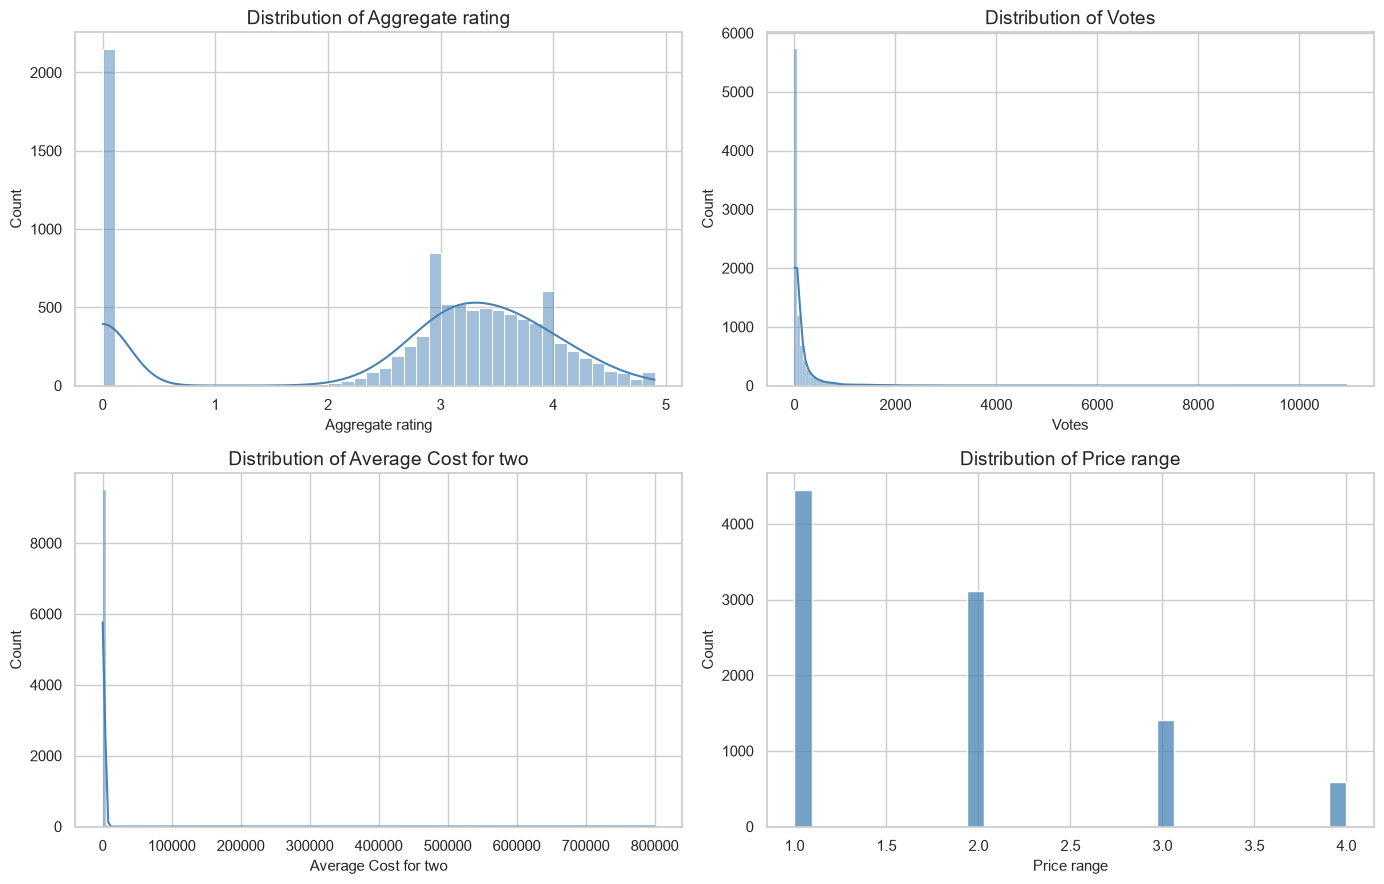

In [5]:
key_numeric = [col for col in ["Aggregate rating", "Votes", "Average Cost for two", "Price range"] if col in df.columns]
if key_numeric:
    ncols = 2
    nrows = int(np.ceil(len(key_numeric) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.5 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, key_numeric):
        sns.histplot(df[col].dropna(), kde=(df[col].nunique() > 10), ax=ax, color="steelblue")
        ax.set_title(f"Distribution of {col}")
        ax.set_xlabel(col)
    for ax in axes[len(key_numeric):]:
        ax.remove()
    plt.tight_layout()
    plt.show()

## 5. Categorical variable distributions

For each requested categorical variable, the frequency table shows the most common values. `Cuisines` can contain multiple cuisines in one cell; therefore, the cuisine-specific analysis below splits comma-separated entries so each listed cuisine is counted individually.

In [6]:
for col in ["Country Code", "City", "Cuisines"]:
    if col in df.columns:
        print(f"\nTop 10 values for {col}:")
        display(df[col].fillna("Missing").value_counts().head(10).rename_axis(col).reset_index(name="Restaurant Records"))


Top 10 values for Country Code:


,Country Code,Restaurant Records
0,1,8652
1,216,434
2,215,80
3,30,60
4,214,60
5,189,60
6,148,40
7,208,34
8,14,24
9,162,22



Top 10 values for City:


,City,Restaurant Records
0,New Delhi,5473
1,Gurgaon,1118
2,Noida,1080
3,Faridabad,251
4,Ghaziabad,25
5,Ahmedabad,21
6,Amritsar,21
7,Bhubaneshwar,21
8,Guwahati,21
9,Lucknow,21



Top 10 values for Cuisines:


,Cuisines,Restaurant Records
0,North Indian,936
1,"North Indian, Chinese",511
2,Chinese,354
3,Fast Food,354
4,"North Indian, Mughlai",334
5,Cafe,299
6,Bakery,218
7,"North Indian, Mughlai, Chinese",197
8,"Bakery, Desserts",170
9,Street Food,149


## 6. Top 10 cities by number of restaurants

,City,Restaurant Count
0,New Delhi,5473
1,Gurgaon,1118
2,Noida,1080
3,Faridabad,251
4,Ghaziabad,25
5,Amritsar,21
6,Bhubaneshwar,21
7,Lucknow,21
8,Ahmedabad,21
9,Guwahati,21


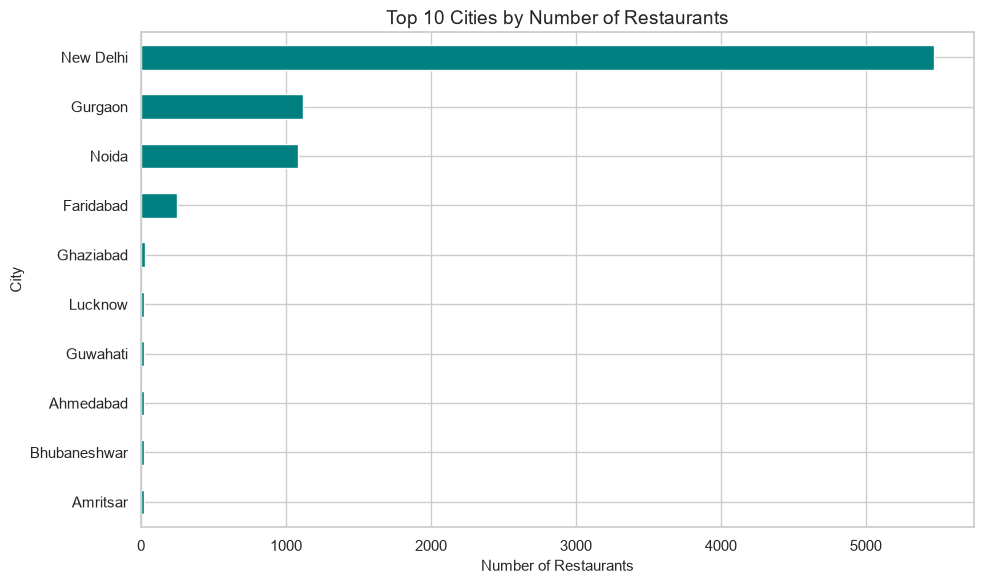

In [7]:
if "City" in df.columns:
    city_counts = (
        df["City"].dropna().astype(str).str.strip()
        .replace("", np.nan).dropna()
        .value_counts().head(10)
        .sort_values(ascending=True)
    )
    display(city_counts.sort_values(ascending=False).rename_axis("City").reset_index(name="Restaurant Count"))

    ax = city_counts.plot(kind="barh", figsize=(10, 6), color="teal")
    ax.set_title("Top 10 Cities by Number of Restaurants")
    ax.set_xlabel("Number of Restaurants")
    ax.set_ylabel("City")
    plt.tight_layout()
    plt.show()
else:
    print("The dataset does not contain a 'City' column.")

## 7. Top 10 cuisines

,Cuisine,Listings
0,North Indian,3960
1,Chinese,2735
2,Fast Food,1986
3,Mughlai,995
4,Italian,764
5,Bakery,745
6,Continental,736
7,Cafe,703
8,Desserts,653
9,South Indian,636


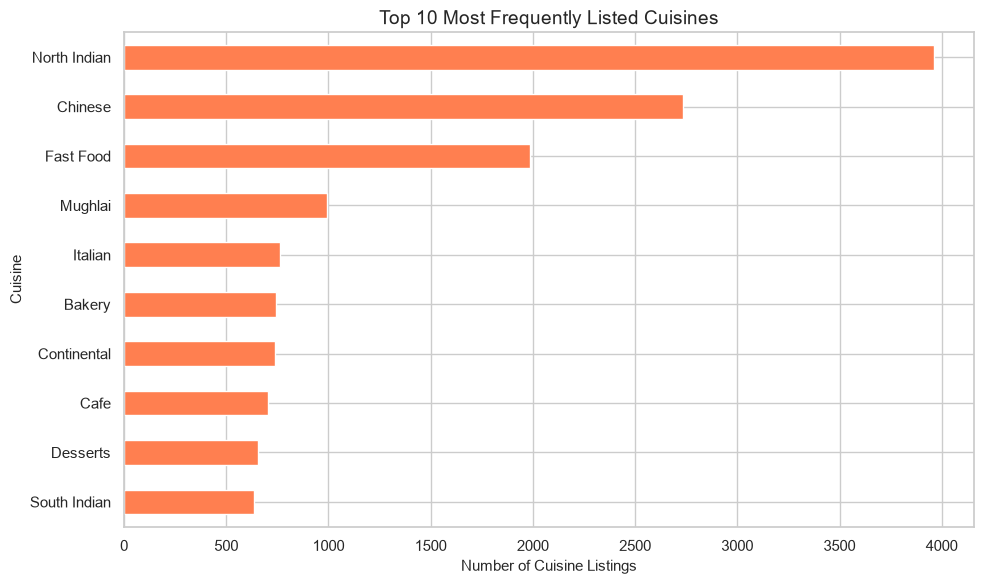

In [8]:
if "Cuisines" in df.columns:
    cuisine_series = (
        df["Cuisines"].dropna().astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )
    cuisine_series = cuisine_series[cuisine_series.ne("") & cuisine_series.str.lower().ne("nan")]
    cuisine_counts = cuisine_series.value_counts().head(10)

    display(cuisine_counts.rename_axis("Cuisine").reset_index(name="Listings"))
    ax = cuisine_counts.sort_values().plot(kind="barh", figsize=(10, 6), color="coral")
    ax.set_title("Top 10 Most Frequently Listed Cuisines")
    ax.set_xlabel("Number of Cuisine Listings")
    ax.set_ylabel("Cuisine")
    plt.tight_layout()
    plt.show()
else:
    print("The dataset does not contain a 'Cuisines' column.")

## 8. Country distribution

This section displays the 10 most represented country codes. A country code is an identifier, not a country name; use a mapping table if readable country names are required.

,Country Code,Restaurant Count
0,1,8652
1,216,434
2,215,80
3,30,60
4,214,60
5,189,60
6,148,40
7,208,34
8,14,24
9,162,22


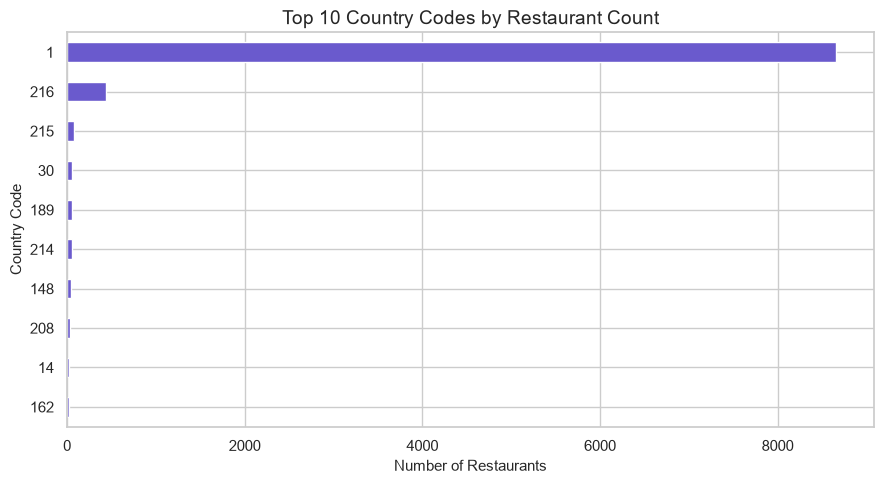

In [9]:
if "Country Code" in df.columns:
    country_counts = df["Country Code"].value_counts().head(10)
    display(country_counts.rename_axis("Country Code").reset_index(name="Restaurant Count"))

    ax = country_counts.sort_values().plot(kind="barh", figsize=(9, 5), color="slateblue")
    ax.set_title("Top 10 Country Codes by Restaurant Count")
    ax.set_xlabel("Number of Restaurants")
    ax.set_ylabel("Country Code")
    plt.tight_layout()
    plt.show()

## 9. Rating summary by city

For the 10 cities with the most records, compare the mean aggregate rating. The number of records is included to provide context; cities with very few records can have less stable averages.

,City,Restaurant_Count,Mean_Aggregate_Rating,Median_Aggregate_Rating
8,New Delhi,5473,2.44,3.1
5,Gurgaon,1118,2.65,3.2
9,Noida,1080,2.04,2.8
3,Faridabad,251,1.87,2.8
4,Ghaziabad,25,2.85,3.2
0,Ahmedabad,21,4.16,4.2
1,Amritsar,21,3.69,3.6
2,Bhubaneshwar,21,3.98,4.0
7,Lucknow,21,4.20,4.2
6,Guwahati,21,4.19,4.1


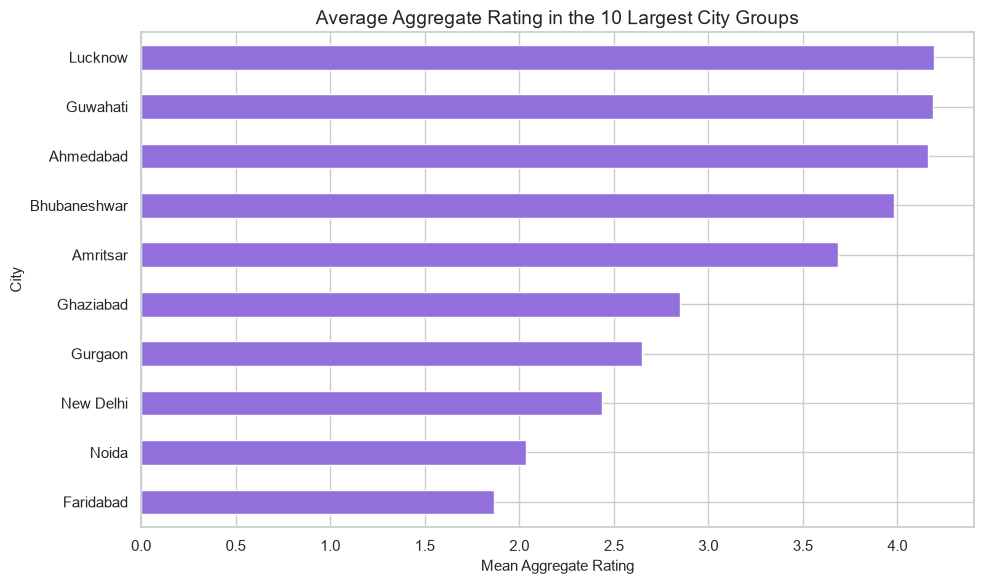

In [10]:
if {"City", "Aggregate rating"}.issubset(df.columns):
    top_city_names = df["City"].dropna().value_counts().head(10).index
    city_rating_summary = (
        df[df["City"].isin(top_city_names)]
        .groupby("City", as_index=False)
        .agg(
            Restaurant_Count=("Restaurant ID", "count") if "Restaurant ID" in df.columns else ("City", "size"),
            Mean_Aggregate_Rating=("Aggregate rating", "mean"),
            Median_Aggregate_Rating=("Aggregate rating", "median")
        )
        .sort_values("Restaurant_Count", ascending=False)
    )
    display(city_rating_summary.round(2))

    plot_data = city_rating_summary.sort_values("Mean_Aggregate_Rating", ascending=True)
    ax = plot_data.plot(
        x="City", y="Mean_Aggregate_Rating", kind="barh",
        legend=False, figsize=(10, 6), color="mediumpurple"
    )
    ax.set_title("Average Aggregate Rating in the 10 Largest City Groups")
    ax.set_xlabel("Mean Aggregate Rating")
    ax.set_ylabel("City")
    plt.tight_layout()
    plt.show()

## 10. Key findings and automatically generated insights

In [11]:
insights = []

if "City" in df.columns:
    city_counts_all = df["City"].dropna().astype(str).str.strip().replace("", np.nan).dropna().value_counts()
    if not city_counts_all.empty:
        insights.append(
            f"**Largest city group:** {city_counts_all.index[0]} has {city_counts_all.iloc[0]:,} restaurant records."
        )
        insights.append(f"**City coverage:** {city_counts_all.nunique():,} distinct city-count frequencies are represented across {city_counts_all.size:,} non-missing city names.")

if "Cuisines" in df.columns:
    cuisine_all = df["Cuisines"].dropna().astype(str).str.split(",").explode().str.strip()
    cuisine_all = cuisine_all[cuisine_all.ne("") & cuisine_all.str.lower().ne("nan")].value_counts()
    if not cuisine_all.empty:
        insights.append(
            f"**Most frequently listed cuisine:** {cuisine_all.index[0]} ({cuisine_all.iloc[0]:,} listings)."
        )

if "Aggregate rating" in df.columns:
    rating = pd.to_numeric(df["Aggregate rating"], errors="coerce").dropna()
    if not rating.empty:
        insights.append(
            f"**Aggregate rating:** mean = {rating.mean():.2f}, median = {rating.median():.2f}, standard deviation = {rating.std():.2f}."
        )
        zero_pct = (rating.eq(0).mean() * 100)
        insights.append(f"**Zero ratings:** {zero_pct:.1f}% of non-missing aggregate ratings are 0.0; consider this when interpreting rating distributions.")

if "Votes" in df.columns:
    votes = pd.to_numeric(df["Votes"], errors="coerce").dropna()
    if not votes.empty:
        insights.append(f"**Votes:** median = {votes.median():.0f}, mean = {votes.mean():.1f}; a large gap between these values can indicate a right-skewed distribution.")

if not insights:
    print("No expected analysis columns were found. Review the dataset schema.")
else:
    for i, insight in enumerate(insights, start=1):
        display(__import__("IPython").display.Markdown(f"{i}. {insight}"))

1. **Largest city group:** New Delhi has 5,473 restaurant records.

2. **City coverage:** 16 distinct city-count frequencies are represented across 141 non-missing city names.

3. **Most frequently listed cuisine:** North Indian (3,960 listings).

4. **Aggregate rating:** mean = 2.67, median = 3.20, standard deviation = 1.52.

5. **Zero ratings:** 22.5% of non-missing aggregate ratings are 0.0; consider this when interpreting rating distributions.

6. **Votes:** median = 31, mean = 156.9; a large gap between these values can indicate a right-skewed distribution.

## 11. Conclusion

This descriptive analysis summarizes the restaurant dataset using numerical statistics, categorical frequency tables, and visualizations. The top-city analysis counts restaurant records by city, while the cuisine analysis splits multi-cuisine cells and counts each cuisine listing separately. Interpret averages alongside medians and distributions, particularly where numerical variables may be skewed or contain zero ratings.

### Task 2 checklist
- [x] Calculate basic statistics for numerical columns.
- [x] Explore `Country Code`, `City`, and `Cuisines` distributions.
- [x] Identify and visualize the top 10 cities by restaurant count.
- [x] Identify and visualize the top 10 cuisines by listing count.
- [x] Summarize key findings from the dataset.

**Reproducibility note:** The notebook reads the dataset from `../dataset/Dataset.csv`; keep the existing `Dataset/` and `Level1/` folders unchanged.